### 1. Formulate at least two hypotheses from the dataset. Example:
H₀: Smoking has no effect on Diabetes prevalence.

H₁: Smoking affects Diabetes prevalence.


In [12]:
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_csv("Health_data.csv")
alpha = 0.05 

prevalence = df.groupby("smoking_status")["diabetes"].mean() * 100
print(prevalence.round(1))

smoking_status
Former Smoker    22.0
Non-Smoker        6.8
Smoker           19.0
Name: diabetes, dtype: float64


In [7]:
# --- Hypothesis 1 ---
H0_1 = "Smoking has no effect on Diabetes prevalence."
H1_1 = "Smoking affects Diabetes prevalence."

observed = pd.crosstab(df["smoking_status"], df["diabetes"])
chi2_score, p_value_1, dof, expected = stats.chi2_contingency(observed)
critical_chi2 = stats.chi2.ppf(1 - alpha, dof)

print("\nH0:", H0_1)
print("H1:", H1_1)
print("Chi-square =", round(chi2_score, 2),
      "| Critical =", round(critical_chi2, 2),
      "| p-value =", round(p_value_1, 4))

if p_value_1 < alpha:
    print("Decision: Reject H0 -> There is a significant relationship between Smoking and Diabetes.")
else:
    print("Decision: Fail to reject H0 -> There is no significant relationship between Smoking and Diabetes.")


H0: Smoking has no effect on Diabetes prevalence.
H1: Smoking affects Diabetes prevalence.
Chi-square = 8.42 | Critical = 5.99 | p-value = 0.0148
Decision: Reject H0 -> There is a significant relationship between Smoking and Diabetes.


In [8]:
# --- Hypothesis 2 ---
H0_2 = "Mean blood pressure of Smokers = Mean blood pressure of Non-Smokers."
H1_2 = "Mean blood pressure of Smokers != Mean blood pressure of Non-Smokers."

bp_smoker = df[df["smoking_status"] == "Smoker"]["blood_pressure"]
bp_nonsmoker = df[df["smoking_status"] == "Non-Smoker"]["blood_pressure"]

t_score, p_value_2 = stats.ttest_ind(bp_smoker, bp_nonsmoker, equal_var=False)
critical_t = stats.t.ppf(1 - alpha/2, len(bp_smoker) + len(bp_nonsmoker) - 2)

print("\nH0:", H0_2)
print("H1:", H1_2)
print("t =", round(t_score, 2),
      "| Critical =", round(critical_t, 3),
      "| p-value =", round(p_value_2, 4))

print("Decision:", "Reject H0" if p_value_2 < alpha else "Fail to reject H0")


H0: Mean blood pressure of Smokers = Mean blood pressure of Non-Smokers.
H1: Mean blood pressure of Smokers != Mean blood pressure of Non-Smokers.
t = 0.42 | Critical = 1.975 | p-value = 0.6766
Decision: Fail to reject H0


### 2. Calculate Confidence Intervals for key numerical data like age, weight, etc.

In [11]:

confidence = 0.95
alpha = 1 - confidence

numeric_cols = ["age", "weight", "bmi", "blood_pressure", "cholesterol_level", "glucose_level"]

results = []

for col in numeric_cols:
    data = df[col]
    n = len(data)                     
    x_bar = data.mean()                 
    s = data.std(ddof=1)                
    std_error = stats.sem(data) 
    critical_t = stats.t.ppf(1 - alpha/2, n - 1)
    margin_of_error = critical_t * std_error

    ci_lower, ci_upper = stats.t.interval(confidence, n - 1, loc=x_bar, scale=std_error)

    results.append([col, n, round(x_bar, 2), round(s, 2), round(std_error, 3), round(critical_t, 3), round(margin_of_error, 2), round(ci_lower, 2), round(ci_upper, 2)])

ci_table = pd.DataFrame(results, columns=["variable", "n", "mean", "std", "std_error", "t_critical", "margin_of_error", "ci_lower", "ci_upper"])
print(ci_table.to_string(index=False))

         variable   n   mean   std  std_error  t_critical  margin_of_error  ci_lower  ci_upper
              age 200  44.26 16.97      1.200       1.972             2.37     41.89     46.62
           weight 200  69.39 12.27      0.868       1.972             1.71     67.67     71.10
              bmi 200  24.74  3.41      0.241       1.972             0.48     24.26     25.21
   blood_pressure 200 124.65 11.71      0.828       1.972             1.63    123.02    126.28
cholesterol_level 200 188.37 24.33      1.720       1.972             3.39    184.98    191.77
    glucose_level 200  98.94 20.77      1.469       1.972             2.90     96.04    101.84


### 3. Find the Critical Value and p-value to interpret the test results

In [14]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import norm

df = pd.read_csv("health_data.csv")
alpha = 0.05
n = len(df)
results = []

def decision(p_value, alpha=0.05):
    return "Reject H0" if p_value < alpha else "Fail to reject H0"

# ---------- 1. z-test (BMI, H0: mu = 24) ----------
mu, sigma = 24, 4
z_score = (df["bmi"].mean() - mu) / (sigma / np.sqrt(n))
p_value_z = 2 * (1 - norm.cdf(abs(z_score)))
critical_z = norm.ppf(1 - alpha/2)
results.append(["z-test (BMI, mu=24)", round(z_score, 3), f"±{critical_z:.3f}",
                p_value_z, decision(p_value_z)])

# ---------- 2. t-test (BP: Smoker vs Non-Smoker) ----------
bp_smoker = df[df["smoking_status"] == "Smoker"]["blood_pressure"]
bp_nonsmoker = df[df["smoking_status"] == "Non-Smoker"]["blood_pressure"]
t_score, p_value_t = stats.ttest_ind(bp_smoker, bp_nonsmoker, equal_var=True)
dof_t = len(bp_smoker) + len(bp_nonsmoker) - 2
critical_t = stats.t.ppf(1 - alpha/2, dof_t)
results.append([f"t-test (BP, df={dof_t})", round(t_score, 3), f"±{critical_t:.3f}",
                p_value_t, decision(p_value_t)])

# ---------- 3. Chi-square (Smoking vs Diabetes) ----------
observed = pd.crosstab(df["smoking_status"], df["diabetes"])
chi2_score, p_value_chi, dof_chi, expected = stats.chi2_contingency(observed)
critical_chi2 = stats.chi2.ppf(1 - alpha, dof_chi)
results.append([f"Chi-square (df={dof_chi})", round(chi2_score, 3), f"{critical_chi2:.3f}",
                p_value_chi, decision(p_value_chi)])

# ---------- 4. ANOVA (BMI across age groups) ----------
bmi_groups = [g["bmi"].values for _, g in df.groupby("age_group")]
f_score, p_value_f = stats.f_oneway(*bmi_groups)
df_between = len(bmi_groups) - 1
df_within = n - len(bmi_groups)
critical_f = stats.f.ppf(1 - alpha, df_between, df_within)
results.append([f"ANOVA (df={df_between},{df_within})", round(f_score, 3), f"{critical_f:.3f}",
                p_value_f, decision(p_value_f)])

# ---------- 5. Correlation (Age vs BMI) ----------
r, p_value_r = stats.pearsonr(df["age"], df["bmi"])
t_corr = r * np.sqrt((n - 2) / (1 - r**2))
critical_t_corr = stats.t.ppf(1 - alpha/2, n - 2)
results.append([f"Correlation (df={n-2})", round(t_corr, 3), f"±{critical_t_corr:.3f}",
                p_value_r, decision(p_value_r)])

summary = pd.DataFrame(results, columns=["Test", "Test statistic", "Critical value",
                                         "p-value", "Decision"])
pd.set_option("display.float_format", lambda x: f"{x:.6g}")
print(summary.to_string(index=False))

                Test  Test statistic Critical value     p-value          Decision
 z-test (BMI, mu=24)           2.609         ±1.960  0.00907478         Reject H0
 t-test (BP, df=157)           0.451         ±1.975    0.652676 Fail to reject H0
   Chi-square (df=2)           8.424          5.991   0.0148131         Reject H0
    ANOVA (df=4,195)           8.617          2.418 2.00458e-06         Reject H0
Correlation (df=198)           5.961         ±1.972 1.13454e-08         Reject H0


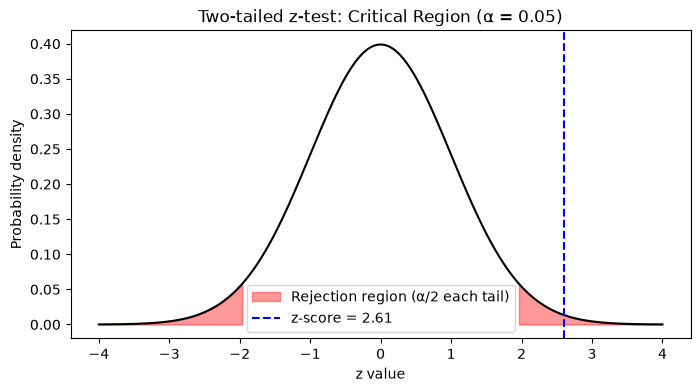

In [17]:
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 500)
y = norm.pdf(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y, color="black")
plt.fill_between(x, y, where=(x <= -critical_z), color="red", alpha=0.4, label="Rejection region (α/2 each tail)")
plt.fill_between(x, y, where=(x >= critical_z), color="red", alpha=0.4)
plt.axvline(z_score, color="blue", linestyle="--", label=f"z-score = {z_score:.2f}")
plt.title("Two-tailed z-test: Critical Region (α = 0.05)")
plt.xlabel("z value")
plt.ylabel("Probability density")
plt.legend()
plt.show()

### 4. Perform z-test or t-test based on sample size (mean comparison across groups).


In [18]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import norm

df = pd.read_csv("health_data.csv")
alpha = 0.05

def decision(p_value, alpha=0.05):
    return "Reject H0" if p_value < alpha else "Fail to reject H0"

def two_sample_tests(group1, group2):
    n1, n2 = len(group1), len(group2)
    # t-test (σ unknown)
    t_score, p_value_t = stats.ttest_ind(group1, group2, equal_var=True)
    critical_t = stats.t.ppf(1 - alpha/2, n1 + n2 - 2)
    # z-test (large samples, sample std used as estimate)
    se = np.sqrt(group1.var(ddof=1)/n1 + group2.var(ddof=1)/n2)
    z_score = (group1.mean() - group2.mean()) / se
    p_value_z = 2 * (1 - norm.cdf(abs(z_score)))
    critical_z = norm.ppf(1 - alpha/2)
    print(f"n1 = {n1}, n2 = {n2} | mean1 = {group1.mean():.2f}, mean2 = {group2.mean():.2f}")
    print(f"t-test: t = {t_score:.3f} | critical = ±{critical_t:.3f} | p = {p_value_t:.4g} -> {decision(p_value_t)}")
    print(f"z-test: z = {z_score:.3f} | critical = ±{critical_z:.3f} | p = {p_value_z:.4g} -> {decision(p_value_z)}")

# ---------- Test 1: BP of Smokers vs Non-Smokers ----------
# H0: mean BP (Smoker) = mean BP (Non-Smoker)    H1: they are different
print("TEST 1: Blood pressure, Smoker vs Non-Smoker")
bp_smoker = df[df["smoking_status"] == "Smoker"]["blood_pressure"]
bp_nonsmoker = df[df["smoking_status"] == "Non-Smoker"]["blood_pressure"]
two_sample_tests(bp_smoker, bp_nonsmoker)

# ---------- Test 2: BMI of Daily vs Never exercisers ----------
# H0: mean BMI (Daily) = mean BMI (Never)    H1: they are different
print("\nTEST 2: BMI, Daily vs Never exercise")
bmi_daily = df[df["exercise_frequency"] == "Daily"]["bmi"]
bmi_never = df[df["exercise_frequency"] == "Never"]["bmi"]
two_sample_tests(bmi_daily, bmi_never)

# ---------- Test 3: Small sample (n = 15), one-sample t-test ----------
# H0: mu = 24    H1: mu != 24
print("\nTEST 3: One-sample t-test, small sample (n = 15)")
small_sample = df["bmi"].sample(15, random_state=7)
t_score, p_value = stats.ttest_1samp(small_sample, popmean=24)
critical_t = stats.t.ppf(1 - alpha/2, len(small_sample) - 1)
print(f"x_bar = {small_sample.mean():.2f} | t = {t_score:.3f} | critical = ±{critical_t:.3f} "
      f"| p = {p_value:.4f} -> {decision(p_value)}")

TEST 1: Blood pressure, Smoker vs Non-Smoker
n1 = 42, n2 = 117 | mean1 = 125.78, mean2 = 124.81
t-test: t = 0.451 | critical = ±1.975 | p = 0.6527 -> Fail to reject H0
z-test: z = 0.419 | critical = ±1.960 | p = 0.6752 -> Fail to reject H0

TEST 2: BMI, Daily vs Never exercise
n1 = 28, n2 = 35 | mean1 = 22.44, mean2 = 27.21
t-test: t = -6.124 | critical = ±2.000 | p = 7.226e-08 -> Reject H0
z-test: z = -6.185 | critical = ±1.960 | p = 6.199e-10 -> Reject H0

TEST 3: One-sample t-test, small sample (n = 15)
x_bar = 25.09 | t = 1.831 | critical = ±2.145 | p = 0.0884 -> Fail to reject H0


### 5. Conduct a chi-square test on categorical data (e.g., Smoking habit vs Disease).

In [25]:
# Chi-Square Test (Test of Independence)
# H0: Smoking has no effect on Diabetes prevalence.
# H1: Smoking affects Diabetes prevalence.

import numpy as np
import pandas as pd
from scipy import stats

data = pd.read_csv("health_data.csv")

# -----------------------------
# Step 1: Observed Frequencies
# (Contingency table: Smoking status vs Diabetes)
# -----------------------------
contingency = pd.crosstab(data["smoking_status"], data["diabetes"])
print(contingency)

observed = contingency.values

# -----------------------------
# Step 2: Expected Frequencies
# E = (row_total * column_total) / grand_total
# -----------------------------
row_total = observed.sum(axis=1, keepdims=True)
col_total = observed.sum(axis=0, keepdims=True)
total = observed.sum()

expected = row_total * col_total / total

# -----------------------------
# Step 3: Manual Chi-Square Statistic
# χ² = Σ (O - E)^2 / E
# -----------------------------
chi_square_stat = ((observed - expected) ** 2 / expected).sum()

# -----------------------------
# Step 4: Degrees of Freedom
# df = (rows - 1) * (columns - 1)
# -----------------------------
rows, cols = observed.shape
df = (rows - 1) * (cols - 1)

# -----------------------------
# Step 5: Calculate p-value and critical_value
# -----------------------------
alpha = 0.05

p_value = 1 - stats.chi2.cdf(chi_square_stat, df)
critical_value = stats.chi2.ppf(1 - alpha, df)

# -----------------------------
# Step 6: Decision (from critical_value)
# -----------------------------
if chi_square_stat > critical_value:
    decision = "Reject H0"
else:
    decision = "Fail to Reject H0"

# -----------------------------
# Final Output
# -----------------------------
print("\nObserved:\n", observed)
print("\nExpected:\n", expected.round(2))
print("\nChi-Square Statistic:", chi_square_stat)
print("Degrees of Freedom:", df)
print("p-value:", p_value)
print("Critical Value:", critical_value)
print("Decision:", decision)

diabetes        False  True 
smoking_status              
Former Smoker      32      9
Non-Smoker        109      8
Smoker             34      8

Observed:
 [[ 32   9]
 [109   8]
 [ 34   8]]

Expected:
 [[ 35.88   5.12]
 [102.38  14.62]
 [ 36.75   5.25]]

Chi-Square Statistic: 8.42448298894292
Degrees of Freedom: 2
p-value: 0.01481312755397024
Critical Value: 5.991464547107979
Decision: Reject H0


### 6. Perform an ANOVA test to check if age groups significantly differ in disease rate.

In [26]:
import numpy as np
import pandas as pd
from scipy import stats

data = pd.read_csv("health_data.csv")

# True/False -> 1/0
data["hypertension_num"] = data["hypertension"].astype(int)

age_18_25 = data[data["age_group"] == "18-25"]["hypertension_num"].values
age_26_35 = data[data["age_group"] == "26-35"]["hypertension_num"].values
age_36_45 = data[data["age_group"] == "36-45"]["hypertension_num"].values
age_46_60 = data[data["age_group"] == "46-60"]["hypertension_num"].values
age_60_plus = data[data["age_group"] == "60+"]["hypertension_num"].values

groups = [age_18_25, age_26_35, age_36_45, age_46_60, age_60_plus]

all_data = np.concatenate(groups)
grand_mean = np.mean(all_data)

SSB = sum(len(g) * (np.mean(g) - grand_mean)**2 for g in groups)
SSW = sum(sum((g - np.mean(g))**2) for g in groups)

k = len(groups)
N = len(all_data)

df_between = k - 1
df_within = N - k

MSB = SSB / df_between
MSW = SSW / df_within

F_statistic = MSB / MSW

print("Grand mean:", grand_mean)
print("SSB:", SSB, "| SSW:", SSW)
print("df_between:", df_between, "| df_within:", df_within)
print("MSB:", MSB, "| MSW:", MSW)
print("F_statistic:", F_statistic)

Grand mean: 0.225
SSB: 3.8580969242733953 | SSW: 31.016903075726596
df_between: 4 | df_within: 195
MSB: 0.9645242310683488 | MSW: 0.15906104141398253
F_statistic: 6.063862165707917


In [27]:
# Auto check using scipy
F_auto, p_value = stats.f_oneway(age_18_25, age_26_35, age_36_45, age_46_60, age_60_plus)

alpha = 0.05
critical_F = stats.f.ppf(1 - alpha, df_between, df_within)

print("F_auto:", F_auto)
print("p_value:", p_value)
print("critical_F:", critical_F)

F_auto: 6.063862165707914
p_value: 0.00012796182123355602
critical_F: 2.417962541843985


In [28]:
if p_value < alpha:
    print("The p-value is less than 0.05, so we reject the null hypothesis. At least one age group differs significantly in hypertension rate.")
else:
    print("The p-value is greater than or equal to 0.05, so we fail to reject the null hypothesis. No significant difference among age groups.")

if F_statistic > critical_F:
    print("The F-statistic is greater than the critical value, so we reject the null hypothesis.")
else:
    print("The F-statistic is not greater than the critical value, so we fail to reject the null hypothesis.")

The p-value is less than 0.05, so we reject the null hypothesis. At least one age group differs significantly in hypertension rate.
The F-statistic is greater than the critical value, so we reject the null hypothesis.


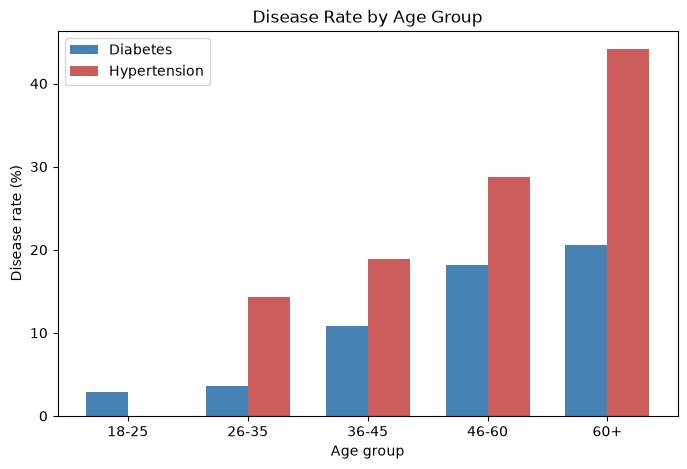

In [31]:
import matplotlib.pyplot as plt

order = ["18-25", "26-35", "36-45", "46-60", "60+"]
data["diabetes_num"] = data["diabetes"].astype(int)

diabetes_rate = data.groupby("age_group")["diabetes_num"].mean().reindex(order) * 100
hyper_rate = data.groupby("age_group")["hypertension_num"].mean().reindex(order) * 100

x = np.arange(len(order))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, diabetes_rate, width, label="Diabetes", color="steelblue")
plt.bar(x + width/2, hyper_rate, width, label="Hypertension", color="indianred")
plt.xticks(x, order)
plt.title("Disease Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("Disease rate (%)")
plt.legend()
plt.show()

### 7. Calculate Covariance and Correlation between continuous variables (e.g., Age vs. BMI).

In [32]:
x = data["age"].values
y = data["bmi"].values

# -----------------------------
# Step 1: Means
# -----------------------------
n = len(x)
x_mean = np.mean(x)
y_mean = np.mean(y)

# -----------------------------
# Step 2: Covariance (manual)
# cov = Σ (x - x_mean)(y - y_mean) / (n - 1)
# -----------------------------
covariance = sum((x - x_mean) * (y - y_mean)) / (n - 1)

# -----------------------------
# Step 3: Standard deviations and Correlation (manual)
# r = cov / (std_x * std_y)
# -----------------------------
std_x = np.sqrt(sum((x - x_mean) ** 2) / (n - 1))
std_y = np.sqrt(sum((y - y_mean) ** 2) / (n - 1))

correlation = covariance / (std_x * std_y)

print("n:", n)
print("Mean Age:", x_mean, "| Mean BMI:", y_mean)
print("Covariance (manual):", covariance)
print("Std Age:", std_x, "| Std BMI:", std_y)
print("Correlation r (manual):", correlation)
print("R-squared:", correlation ** 2)

n: 200
Mean Age: 44.255 | Mean BMI: 24.738000000000003
Covariance (manual): 22.55307537688442
Std Age: 16.972338565498553 | Std BMI: 3.4068001757053397
Correlation r (manual): 0.39004743288365756
R-squared: 0.15213699989913135


In [33]:
# -----------------------------
# Step 4: Auto check (NumPy / SciPy)
# -----------------------------
cov_auto = np.cov(x, y)[0, 1]
corr_auto = np.corrcoef(x, y)[0, 1]
r_scipy, p_value = stats.pearsonr(x, y)

print("Covariance (np.cov):", cov_auto)
print("Correlation (np.corrcoef):", corr_auto)
print("Pearson r (scipy):", r_scipy, "| p-value:", p_value)

Covariance (np.cov): 22.553075376884422
Correlation (np.corrcoef): 0.3900474328836576
Pearson r (scipy): 0.3900474328836577 | p-value: 1.134543542931972e-08


In [34]:
# -----------------------------
# Step 5: Significance test of correlation
# t = r * sqrt((n - 2) / (1 - r^2)),  df = n - 2
# -----------------------------
alpha = 0.05
df = n - 2

t_statistic = correlation * np.sqrt(df / (1 - correlation ** 2))
critical_t = stats.t.ppf(1 - alpha / 2, df)

print("t_statistic:", t_statistic, "| critical_t:", critical_t, "| p_value:", p_value)

if p_value < alpha:
    print("The p-value is less than 0.05, so we reject H0. Age and BMI are significantly correlated.")
else:
    print("The p-value is greater than or equal to 0.05, so we fail to reject H0. No significant correlation.")

t_statistic: 5.960561554755505 | critical_t: 1.9720174778363146 | p_value: 1.134543542931972e-08
The p-value is less than 0.05, so we reject H0. Age and BMI are significantly correlated.


### 8. Clearly state the result and interpretation (Accept/Reject H₀) of each test performed.


In [42]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import norm

data = pd.read_csv("health_data.csv")
alpha = 0.05
n = len(data)
results = []

def add_result(no, test, H0, statistic, critical, p_value):
    decision = "Reject H0" if p_value < alpha else "Accept H0 (Fail to reject)"
    results.append([no, test, H0, round(statistic, 3), round(critical, 3),
                    float(f"{p_value:.4g}"), decision])

# 1. Chi-square: Smoking vs Diabetes
observed = pd.crosstab(data["smoking_status"], data["diabetes"])
chi2_score, p_value, dof, expected = stats.chi2_contingency(observed)
add_result(1, "Chi-square: Smoking vs Diabetes", "Smoking has no effect on Diabetes",
           chi2_score, stats.chi2.ppf(1 - alpha, dof), p_value)

# 2. Chi-square: Smoking vs Hypertension
observed = pd.crosstab(data["smoking_status"], data["hypertension"])
chi2_score, p_value, dof, expected = stats.chi2_contingency(observed)
add_result(2, "Chi-square: Smoking vs Hypertension", "Smoking and Hypertension independent",
           chi2_score, stats.chi2.ppf(1 - alpha, dof), p_value)

# 3. z-test: Mean BMI
z_score = (data["bmi"].mean() - 24) / (4 / np.sqrt(n))
p_value = 2 * (1 - norm.cdf(abs(z_score)))
add_result(3, "z-test: Mean BMI", "mu = 24", z_score, norm.ppf(1 - alpha/2), p_value)

# 4. z-test: Mean BP
z_score = (data["blood_pressure"].mean() - 120) / (15 / np.sqrt(n))
p_value = 2 * (1 - norm.cdf(abs(z_score)))
add_result(4, "z-test: Mean BP", "mu = 120", z_score, norm.ppf(1 - alpha/2), p_value)

# 5. t-test: BP Smoker vs Non-Smoker
a = data[data["smoking_status"] == "Smoker"]["blood_pressure"]
b = data[data["smoking_status"] == "Non-Smoker"]["blood_pressure"]
t_score, p_value = stats.ttest_ind(a, b, equal_var=True)
add_result(5, "t-test: BP Smoker vs Non-Smoker", "Mean BP equal", t_score,
           stats.t.ppf(1 - alpha/2, len(a) + len(b) - 2), p_value)

# 6. t-test: BMI Daily vs Never exercise
a = data[data["exercise_frequency"] == "Daily"]["bmi"]
b = data[data["exercise_frequency"] == "Never"]["bmi"]
t_score, p_value = stats.ttest_ind(a, b, equal_var=True)
add_result(6, "t-test: BMI Daily vs Never exercise", "Mean BMI equal", t_score,
           stats.t.ppf(1 - alpha/2, len(a) + len(b) - 2), p_value)

# 7. t-test: small sample (n = 15)
small_sample = data["bmi"].sample(15, random_state=7)
t_score, p_value = stats.ttest_1samp(small_sample, 24)
add_result(7, "t-test: BMI, small sample (n=15)", "mu = 24", t_score,
           stats.t.ppf(1 - alpha/2, 14), p_value)

# 8-10. ANOVA by age group
order = ["18-25", "26-35", "36-45", "46-60", "60+"]
data["hypertension_num"] = data["hypertension"].astype(int)
data["diabetes_num"] = data["diabetes"].astype(int)

anova_list = [(8, "hypertension_num", "ANOVA: Hypertension rate by Age group"),
              (9, "diabetes_num", "ANOVA: Diabetes rate by Age group"),
              (10, "bmi", "ANOVA: BMI by Age group")]

for no, col, name in anova_list:
    groups = [data[data["age_group"] == g][col].values for g in order]
    f_score, p_value = stats.f_oneway(*groups)
    critical_F = stats.f.ppf(1 - alpha, len(groups) - 1, n - len(groups))
    add_result(no, name, "All age-group means equal", f_score, critical_F, p_value)

# 11. Pearson correlation: Age vs BMI
r, p_value = stats.pearsonr(data["age"], data["bmi"])
t_score = r * np.sqrt((n - 2) / (1 - r ** 2))
add_result(11, "Pearson correlation: Age vs BMI", "rho = 0", t_score,
           stats.t.ppf(1 - alpha/2, n - 2), p_value)

# ---------- Final table ----------
summary = pd.DataFrame(results, columns=["No", "Test", "H0", "Statistic",
                                         "Critical value", "p-value", "Decision"])
print(summary.to_string(index=False))
summary.to_csv("results_summary.csv", index=False)

 No                                  Test                                   H0  Statistic  Critical value   p-value                   Decision
  1       Chi-square: Smoking vs Diabetes    Smoking has no effect on Diabetes      8.424           5.991   0.01481                  Reject H0
  2   Chi-square: Smoking vs Hypertension Smoking and Hypertension independent      0.274           5.991    0.8722 Accept H0 (Fail to reject)
  3                      z-test: Mean BMI                              mu = 24      2.609            1.96  0.009075                  Reject H0
  4                       z-test: Mean BP                             mu = 120      4.385            1.96 1.162e-05                  Reject H0
  5       t-test: BP Smoker vs Non-Smoker                        Mean BP equal      0.451           1.975    0.6527 Accept H0 (Fail to reject)
  6   t-test: BMI Daily vs Never exercise                       Mean BMI equal     -6.124               2 7.226e-08                  Reject H0